In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


# JERICHON — SC_08: устойчивость аномалий и проверка режима



## Настройки и ожидаемое время

Используется тот же причинный загрузчик AlgoPack и те же группы признаков, что в SC_07. Этот ноутбук **не ищет заново лучшие группы**: он проверяет заранее зафиксированные кандидаты, выбранные только на ранних 50% данных в SC_07.

- Тикеры: SMLT, GAZP, SPBE, MTLR, YDEX.
- Горизонты: 3, 5 и 10 Dollar Bars.
- Направление: рост, падение, продолжение, разворот.
- Режим: будущий диапазон выше/ниже исторического уровня для того же часа.
- Важное отличие: события прореживаются, чтобы уменьшить перекрытие окон; сравнение доходности остаётся исследовательским прокси, не настоящим бэктестом стратегии.

Ожидаемое время после загрузки данных — обычно минуты, но зависит от локального хранилища AlgoPack.


In [ ]:
from pathlib import Path
import sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["SMLT", "GAZP", "SPBE", "MTLR", "YDEX"]
DOLLAR_THRESHOLD = 10_000_000
ROLLING_WINDOW = 500
MIN_HISTORY = 100
ANOMALY_QUANTILES = (0.95, 0.99)
GROUP_QUANTILES = (0.95, 0.99)
EPISODE_GAP_BARS = 3
MAX_CONTROLS_PER_EVENT = 3
RANDOM_STATE = 17
PROJECT_ROOT = ROOT
DATA_ROOT = PROJECT_ROOT / "data"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source")
missing = [x for x in required_helpers if not hasattr(jfp, x)]
if missing:
    raise RuntimeError(f"В установленном jerichon_feature_pipeline.py отсутствуют helpers: {missing}")

print("Project root:", PROJECT_ROOT)
print("History root:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())
print("Tickers:", TICKERS)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")


Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Tickers: ['SMLT', 'GAZP', 'SPBE', 'MTLR', 'YDEX']
Dollar threshold: 10,000,000


## 2. Построение причинного набора

Повторно используем проверенную загрузку и существующий feature pipeline; контракт 73 + 401 = 474 проверяется до анализа.

In [2]:

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source}; доступны: {list(frames)}")

def build_ticker_dataset(ticker):
    data, saved_dates = load_local_history(ticker, HISTORY_ROOT)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"{ticker}: в bars нет bar_ts/close_time; columns={list(bars.columns)}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

    # The pipeline creates many derived columns by repeated assignment. Its
    # fragmentation PerformanceWarnings are known and are summarized once,
    # rather than flooding the notebook output.
    perf_warning_count = 0
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        base = jfp._base(bars.copy())
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError(f"{ticker}: _base не вернул DataFrame")
    if "bar_ts" not in base.columns:
        if "close_time" in base.columns:
            base = base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base.index, pd.DatetimeIndex):
            base = base.reset_index().rename(columns={base.index.name or "index": "bar_ts"})
        elif "ts" in base.columns:
            base = base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"{ticker}: не найден временной ключ в base features")
    base["bar_ts"] = pd.to_datetime(base["bar_ts"], errors="coerce", utc=True)
    base = base.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")

    bars_sc = bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        close_col = next((c for c in bars_sc.columns if str(c).lower() == "close"), None)
        if close_col is None:
            raise RuntimeError(f"{ticker}: нет CLOSE/close в Dollar Bars")
        bars_sc["CLOSE"] = bars_sc[close_col]
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        sc_result = jfp._build_sc_features(
            data,
            bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True),
        )
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Validate source availability using the pipeline's established helper.
        checked = jfp._choose_availability(data[source].copy(), source)
        if isinstance(checked, tuple):
            checked = checked[0]
        if checked is None or len(checked) == 0:
            raise RuntimeError(f"{ticker}: availability validation вернула пустой {source}")
        ff = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, ff, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols_raw = [c for c in base.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base[c])]
    if len(base_cols_raw) != 73:
        raise RuntimeError(f"{ticker}: ожидалось 73 base features, найдено {len(base_cols_raw)}")
    base_join = base[["bar_ts"] + base_cols_raw].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols_raw})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns if c.startswith(prefixes) and c not in provenance and pd.api.types.is_numeric_dtype(causal[c])]
    # IMPORTANT: test the dtype of the SERIES causal[c], not the column-name
    # string c. Testing c silently dropped all 73 base features.
    base_feature_cols = [
        c for c in causal.columns
        if c.startswith("base__") and pd.api.types.is_numeric_dtype(causal[c])
    ]
    feature_cols = base_feature_cols + sc_cols

    # Validate each block separately so a mismatch reports exactly which block
    # is absent; don't silently skip a ticker or hide the root cause.
    if len(base_feature_cols) != len(base_cols_raw):
        raise RuntimeError(
            f"{ticker}: после merge сохранилось {len(base_feature_cols)} из "
            f"{len(base_cols_raw)} базовых признаков"
        )
    if not sc_cols:
        raise RuntimeError(
            f"{ticker}: после causal attach не найдено числовых SC-признаков. "
            f"Колонки итогового frame: {list(causal.columns)}"
        )
    if len(feature_cols) != 474:
        raise RuntimeError(
            f"{ticker}: состав признаков отличается от ожидаемого: "
            f"base={len(base_feature_cols)} (ожидалось 73), "
            f"SC={len(sc_cols)} (ожидалось 401), total={len(feature_cols)}. "
            "Тикер не будет молча отброшен: проверь названия колонок в pipeline."
        )
    causal = causal.sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    # Keep bar fields for forward path analysis, plus features and provenance.
    if perf_warning_count:
        print(f"{ticker}: подавлено предупреждений о фрагментации DataFrame: {perf_warning_count}")
    return {
        "ticker": ticker, "data": data, "dates": saved_dates, "bars": bars,
        "dataset": causal, "feature_cols": feature_cols, "base_cols": base_feature_cols,
        "sc_cols": sc_cols, "provenance": provenance,
    }

datasets = {}
load_rows = []
load_errors = []
for ticker in TICKERS:
    try:
        obj = build_ticker_dataset(ticker)
        datasets[ticker] = obj
        load_rows.append({
            "ticker": ticker, "saved_dates": len(obj["dates"]),
            "date_start": obj["dates"][0], "date_end": obj["dates"][-1],
            "dollar_bars": len(obj["bars"]), "base_features": len(obj["base_cols"]),
            "supercandle_features": len(obj["sc_cols"]), "features_total": len(obj["feature_cols"]),
        })
        print(
            f"OK {ticker}: bars={len(obj['bars']):,}; "
            f"base={len(obj['base_cols'])}; SC={len(obj['sc_cols'])}; "
            f"dates={obj['dates'][0]} → {obj['dates'][-1]}"
        )
    except Exception as e:
        message = f"{ticker}: {type(e).__name__}: {e}"
        load_errors.append(message)
        print(f"ERROR {message}")
display(pd.DataFrame(load_rows))
if load_errors:
    print("\nОшибки загрузки (кратко):")
    for message in load_errors:
        print(" -", message)
if not datasets:
    raise RuntimeError(
        "Не удалось подготовить данные ни для одного тикера. Причины выше: "
        + " | ".join(load_errors)
    )


SMLT: подавлено предупреждений о фрагментации DataFrame: 74
OK SMLT: bars=2,907; base=73; SC=401; dates=2026-09-25 → 2026-10-23
GAZP: подавлено предупреждений о фрагментации DataFrame: 74
OK GAZP: bars=11,566; base=73; SC=401; dates=2026-09-24 → 2026-10-23
SPBE: подавлено предупреждений о фрагментации DataFrame: 74
OK SPBE: bars=2,503; base=73; SC=401; dates=2026-08-28 → 2026-10-23
MTLR: подавлено предупреждений о фрагментации DataFrame: 74
OK MTLR: bars=1,547; base=73; SC=401; dates=2026-08-28 → 2026-10-23
YDEX: подавлено предупреждений о фрагментации DataFrame: 74
OK YDEX: bars=10,737; base=73; SC=401; dates=2026-08-28 → 2026-10-23


,ticker,saved_dates,date_start,date_end,dollar_bars,base_features,supercandle_features,features_total
0,SMLT,16,2026-09-25,2026-10-23,2907,73,401,474
1,GAZP,17,2026-09-24,2026-10-23,11566,73,401,474
2,SPBE,34,2026-08-28,2026-10-23,2503,73,401,474
3,MTLR,35,2026-08-28,2026-10-23,1547,73,401,474
4,YDEX,34,2026-08-28,2026-10-23,10737,73,401,474


## 3. Свернуть 401 столбец в корневые метрики и смысловые семьи

Например, `x`, `x_ma3`, `x_z12`, `x_chg`, `x_ret` относятся к одному корневому сигналу. Семьи по названиям эвристические и нужны только для первого анализа.

In [3]:
import math, re
from collections import defaultdict

TRANSFORM_RE = re.compile(r"_(?:ma\d+|z\d+|chg|ret)$", re.IGNORECASE)
def root_feature_name(col):
    source, metric = col.split("__", 1)
    while True:
        new_metric = TRANSFORM_RE.sub("", metric)
        if new_metric == metric: break
        metric = new_metric
    return f"{source}__{metric}"
def transform_complexity(col):
    return len(TRANSFORM_RE.findall(col.split("__", 1)[1]))
def semantic_family(root_col):
    m = root_col.split("__", 1)[1].lower()
    if any(k in m for k in ("imb", "imbalance", "bid", "ask", "buy", "sell", "aggress", "b_s", "share")): return "imbalance_pressure"
    if any(k in m for k in ("spread", "liquidity", "cost", "vwap", "px_", "price", "mid", "microprice", "bps")): return "liquidity_price"
    if any(k in m for k in ("volume", "value", "turnover", "trade", "count", "qty", "notional", "amount")): return "activity_volume"
    if any(k in m for k in ("order", "depth", "level", "queue", "cancel", "add", "modify")): return "orders_depth"
    return "other"

# Inventory is shared across tickers; the loader separately validates 73 + 401 = 474 per ticker.
all_sc_cols = datasets[next(iter(datasets))]["sc_cols"]
root_members = defaultdict(list)
for col in all_sc_cols: root_members[root_feature_name(col)].append(col)
root_rows = []
for root, members in sorted(root_members.items()):
    source = root.split("__", 1)[0]
    chosen = root if root in members else sorted(members, key=lambda c:(transform_complexity(c),len(c),c))[0]
    root_rows.append({"root":root,"source":source,"family":semantic_family(root),"chosen_feature":chosen,"variants":len(members),"is_raw_root":chosen==root})
root_map = pd.DataFrame(root_rows)
print(f"401 SC columns collapsed into {root_map.root.nunique()} root metrics")
print("Root metrics by source/family:")
print(root_map.groupby(["source","family"]).size().rename("roots").to_string())
print("\nTransformation variants per root:")
print(root_map.variants.value_counts().sort_index().rename_axis("variants").to_string())


401 SC columns collapsed into 51 root metrics
Root metrics by source/family:
source      family            
obstats     activity_volume        2
            imbalance_pressure     7
            liquidity_price        7
orderstats  activity_volume        4
            imbalance_pressure    13
            liquidity_price        2
            orders_depth           2
tradestats  activity_volume        2
            imbalance_pressure    10
            other                  2

Transformation variants per root:
variants
1     16
11    35


## 4. Причинные групповые scores

Для каждого корневого признака отклонение от rolling median нормируется на прошлый 95-й перцентиль отклонений. Все окна сдвинуты на один бар. Затем групповой score — среднее верхних 20% root-scores; событие — превышение прошлого 95-го или 99-го перцентиля группового score.

In [4]:
def find_ohlc_columns(bars):
    lower = {str(c).lower():c for c in bars.columns}
    out = {k:next((lower[x] for x in names if x in lower),None) for k,names in {
        "open":("open","o"),"high":("high","h"),"low":("low","l"),"close":("close","c")}.items()}
    missing = [k for k,v in out.items() if v is None]
    if missing: raise RuntimeError(f"OHLC columns missing {missing}; columns={list(bars.columns)}")
    return out

def root_scores_for_ticker(obj):
    ds = obj["dataset"].reset_index(drop=True)
    out = {}
    for _, r in root_map.iterrows():
        col = r["chosen_feature"]
        if col not in ds: continue
        x = pd.to_numeric(ds[col],errors="coerce").replace([np.inf,-np.inf],np.nan)
        med = x.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).median().shift(1)
        dev = (x-med).abs()
        scale = dev.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(.95).shift(1)
        out[r["root"]] = dev / scale.where(scale>0)
    return pd.DataFrame(out)

def top_fraction_mean(frame, fraction=.20):
    if frame.shape[1]==0: return pd.Series(np.nan,index=frame.index)
    a=frame.to_numpy(dtype=float).copy(); a[~np.isfinite(a)]=-np.inf; a.sort(axis=1)
    k=max(1,int(math.ceil(frame.shape[1]*fraction))); top=a[:,-k:]
    ok=np.isfinite(top); sums=np.where(ok,top,0).sum(axis=1); counts=ok.sum(axis=1)
    return pd.Series(np.divide(sums,counts,out=np.full(len(frame),np.nan),where=counts>0),index=frame.index)

def group_scores_for_ticker(obj):
    roots=root_scores_for_ticker(obj); meta=root_map.set_index("root"); groups={}
    for source in ("tradestats","obstats","orderstats"):
        cols=[c for c in roots if meta.loc[c,"source"]==source]
        if cols: groups[f"source::{source}"]=top_fraction_mean(roots[cols])
    for (source,family),part in root_map.groupby(["source","family"]):
        cols=[c for c in part.root.tolist() if c in roots]
        if len(cols)>=2: groups[f"source_family::{source}::{family}"]=top_fraction_mean(roots[cols])
    scores=pd.DataFrame(groups)
    flags={}; thresholds={}
    for col in scores:
        for q in GROUP_QUANTILES:
            th=scores[col].rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(q).shift(1)
            thresholds[(col,q)]=th; flags[(col,q)]=scores[col].gt(th)&th.notna()&scores[col].notna()
    return scores,thresholds,flags

group_results={}
for ticker,obj in datasets.items():
    scores,thresholds,flags=group_scores_for_ticker(obj)
    group_results[ticker]={"scores":scores,"thresholds":thresholds,"flags":flags}
    print(f"{ticker}: {scores.shape[1]} source/family groups; {len(scores):,} bars")


SMLT: 13 source/family groups; 2,907 bars
GAZP: 13 source/family groups; 11,566 bars
SPBE: 13 source/family groups; 2,503 bars
MTLR: 13 source/family groups; 1,547 bars
YDEX: 13 source/family groups; 10,737 bars


## SC_08 — фиксированные кандидаты: устойчивость, направление и режим

Сначала строим признаки так же, как в SC_07. Затем проверяем только заранее выбранные группы. Не выбираем их повторно по валидационному или финальному периоду.


## Конфигурация

Все параметры и названия результатов пояснены по-русски. Порог 0,95 означает 95-й процентиль аномальности, 0,99 — 99-й. Издержки в прокси можно изменить под свой инструмент.


In [11]:

from pathlib import Path
import time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("research/supercandles/mark_8/results"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_TEST = OUTPUT_DIR / "SC_07_direction_regime_final_test.csv"
OUT_CANDIDATES = OUTPUT_DIR / "SC_07_candidates_train_validation.csv"
OUT_RULES = OUTPUT_DIR / "SC_07_rule_proxy_final_test.csv"

TRAIN_END = 0.50
VALID_END = 0.75
HORIZONS = (3, 5, 10)
MOVE_PCT = 0.5
TOP_CANDIDATES = 3
BOOTSTRAP_REPS = 100
MIN_EVENTS = 12
COST_ROUND_TRIP_PCT = 0.12  # ориентир 8 б.п. за полный круг; замени на реальные издержки инструмента
SEED = 20261024

print("Схема периодов: 50% выбор кандидатов / 25% подтверждение / 25% финальный тест")
print("Торговые издержки для исследовательского прокси:", COST_ROUND_TRIP_PCT, "% за полный круг")


Схема периодов: 50% выбор кандидатов / 25% подтверждение / 25% финальный тест
Торговые издержки для исследовательского прокси: 0.12 % за полный круг


## 2. Цели будущего поведения

Для каждого сигнального бара считаются результаты на следующих 3, 5 и 10 барах:

- вероятность достижения +0,5% от текущего закрытия;
- вероятность достижения −0,5%;
- вероятность движения на 0,5% в любую сторону;
- доходность закрытия через горизонт;
- продолжение или разворот относительно доходности предыдущего бара;
- будущий диапазон от максимума до минимума.

Режим «необычно широкий диапазон» определяется сравнением будущего диапазона с историческим распределением диапазонов того же горизонта для того же часового интервала. Порог строится только на уже реализованных прошлых наблюдениях.

In [12]:

def bh_adjust(pvals):
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    good = np.isfinite(p)
    if not good.any(): return out
    pv = p[good]
    order = np.argsort(pv)
    ranked = pv[order]
    q = ranked * len(ranked) / np.arange(1, len(ranked)+1)
    q = np.minimum.accumulate(q[::-1])[::-1].clip(0, 1)
    tmp = np.empty_like(q); tmp[order] = q
    out[np.where(good)[0]] = tmp
    return out

def day_boot_delta(event, target, day_ids, reps=300, seed=1):
    event = np.asarray(event, bool)
    target = np.asarray(target, float)
    ok = event & np.isfinite(target)
    ctrl = (~event) & np.isfinite(target)
    ne, nc = int(ok.sum()), int(ctrl.sum())
    if ne < 8 or nc < 8:
        return np.nan, np.nan, np.nan, np.nan, ne, nc
    delta = float(np.mean(target[ok]) - np.mean(target[ctrl]))
    days = pd.unique(day_ids[pd.notna(day_ids)])
    if len(days) < 5:
        return delta, np.nan, np.nan, np.nan, ne, nc
    day_e_sum, day_e_n, day_c_sum, day_c_n = [], [], [], []
    for d in days:
        m = day_ids == d
        em, cm = m & ok, m & ctrl
        day_e_sum.append(float(np.sum(target[em])) if em.any() else 0.0)
        day_e_n.append(int(em.sum()))
        day_c_sum.append(float(np.sum(target[cm])) if cm.any() else 0.0)
        day_c_n.append(int(cm.sum()))
    es, en = np.asarray(day_e_sum), np.asarray(day_e_n)
    cs, cn = np.asarray(day_c_sum), np.asarray(day_c_n)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(reps):
        picked = rng.integers(0, len(days), len(days))
        ne_b, nc_b = en[picked].sum(), cn[picked].sum()
        if ne_b and nc_b:
            boot.append(es[picked].sum()/ne_b - cs[picked].sum()/nc_b)
    if len(boot) < 50:
        return delta, np.nan, np.nan, np.nan, ne, nc
    b = np.asarray(boot)
    lo, hi = np.quantile(b, [.025, .975])
    p = min(1., 2 * min((np.sum(b <= 0)+1)/(len(b)+1), (np.sum(b >= 0)+1)/(len(b)+1)))
    return delta, float(lo), float(hi), float(p), ne, nc

def make_targets(close, high, low, times, max_h=10):
    n = len(close)
    prev_ret = np.full(n, np.nan)
    prev_ret[1:] = close[1:] / close[:-1] - 1
    targets = {}
    from numpy.lib.stride_tricks import sliding_window_view
    for h in range(1, max_h+1):
        # future bars are i+1 ... i+h; result aligned to signal bar i
        count = n-h
        arrays = {k: np.full(n, np.nan) for k in
                  ["up", "down", "either", "future_range", "forward_return", "continuation", "reversal"]}
        if count > 0:
            wh = sliding_window_view(high[1:], h)[:count]
            wl = sliding_window_view(low[1:], h)[:count]
            maxh = np.nanmax(wh, axis=1)
            minl = np.nanmin(wl, axis=1)
            base = close[:count]
            valid = np.isfinite(base) & (base > 0) & np.isfinite(maxh) & np.isfinite(minl)
            up = np.full(count, np.nan); down = np.full(count, np.nan)
            fr = np.full(count, np.nan)
            up[valid] = (maxh[valid]/base[valid]-1)*100
            down[valid] = (1-minl[valid]/base[valid])*100
            fr[valid] = (maxh[valid]-minl[valid])/base[valid]*100
            arrays["up"][:count] = np.where(np.isfinite(up), (up >= MOVE_PCT).astype(float), np.nan)
            arrays["down"][:count] = np.where(np.isfinite(down), (down >= MOVE_PCT).astype(float), np.nan)
            either = np.maximum(up, down)
            arrays["either"][:count] = np.where(np.isfinite(either), (either >= MOVE_PCT).astype(float), np.nan)
            arrays["future_range"][:count] = fr
            fwd = np.full(count, np.nan)
            fwd[valid] = (close[h:h+count][valid]/base[valid]-1)*100
            arrays["forward_return"][:count] = fwd
            prior = prev_ret[:count]
            good = valid & np.isfinite(prior) & (prior != 0) & np.isfinite(fwd)
            cont = np.full(count, np.nan); rev = np.full(count, np.nan)
            cont[good] = (np.sign(fwd[good]) == np.sign(prior[good])).astype(float)
            rev[good] = (np.sign(fwd[good]) != np.sign(prior[good])).astype(float)
            arrays["continuation"][:count] = cont
            arrays["reversal"][:count] = rev
        targets[h] = arrays
    return targets, prev_ret

def get_aligned_market(obj):
    ds = obj["dataset"].reset_index(drop=True)
    bars = obj["bars"].reset_index(drop=True)
    tcol = "bar_ts" if "bar_ts" in ds.columns else "close_time"
    bcol = "bar_ts" if "bar_ts" in bars.columns else "close_time"
    if tcol not in ds or bcol not in bars:
        raise RuntimeError("Нет времени бара для безопасного выравнивания dataset и OHLC.")
    left = ds[[tcol]].copy()
    right = bars.copy()
    if tcol != bcol: right = right.rename(columns={bcol:tcol})
    merged = left.merge(right, on=tcol, how="left", suffixes=("", "_bar"), validate="one_to_one")
    cols = find_ohlc_columns(merged)
    times = pd.to_datetime(merged[tcol], errors="coerce", utc=True)
    close = pd.to_numeric(merged[cols["close"]], errors="coerce").to_numpy(float)
    high = pd.to_numeric(merged[cols["high"]], errors="coerce").to_numpy(float)
    low = pd.to_numeric(merged[cols["low"]], errors="coerce").to_numpy(float)
    good = times.notna().to_numpy() & np.isfinite(close) & (close > 0) & np.isfinite(high) & np.isfinite(low)
    return ds, times, close, high, low, good

def decluster_events(event, gap=3):
    event = np.asarray(event, bool)
    out = np.zeros(len(event), bool)
    last = -10**9
    for i in np.flatnonzero(event):
        if i-last > gap:
            out[i] = True
            last = i
    return out

def group_event_flags(ticker, n):
    flags = group_results[ticker]["flags"]
    result = {}
    for (group, q), series in flags.items():
        a = series.iloc[:n].fillna(False).to_numpy(bool)
        result[(group, float(q))] = decluster_events(a, gap=3)
    return result

def historical_range_regime(range_target, times, horizon, quantile=.70):
    # Порог — расширяющийся квантиль только по прошлым наблюдениям того же часа.
    # Сдвиг на horizon исключает ещё не завершившиеся исторические окна.
    local = times.dt.tz_convert("Europe/Moscow")
    hour = local.dt.hour
    values = pd.Series(np.asarray(range_target, float), index=np.arange(len(range_target)))
    threshold = values.groupby(hour.to_numpy()).transform(
        lambda s: s.shift(horizon).expanding(min_periods=10).quantile(quantile)
    )
    th = threshold.to_numpy()
    rt = np.asarray(range_target, float)
    known = np.isfinite(th) & np.isfinite(rt)
    wide = np.zeros(len(rt), dtype=bool)
    wide[known] = rt[known] > th[known]
    return wide, known

def metric_targets(targets, times, h):
    t = targets[h]
    # Нормализованный режим будущего диапазона — верхние 30% исторических значений того же часа.
    wide, known = historical_range_regime(t["future_range"], times, h, .70)
    return {
        "вероятность_роста_не_менее_0.5_pct": t["up"],
        "вероятность_падения_не_менее_0.5_pct": t["down"],
        "вероятность_движения_в_любую_сторону_0.5_pct": t["either"],
        "продолжение_предыдущего_направления": t["continuation"],
        "разворот_относительно_предыдущего_направления": t["reversal"],
        "будущий_диапазон_pct": t["future_range"],
        "необычно_широкий_диапазон_для_этого_часа": np.where(known, wide.astype(float), np.nan),
        "доходность_до_закрытия_горизонта_pct": t["forward_return"],
    }


In [13]:

from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')

OUTPUT_DIR = Path("research/supercandles/mark_8/results"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_METRICS = OUTPUT_DIR / "SC_08_fixed_candidate_validation.csv"
OUT_EVENTS = OUTPUT_DIR / "SC_08_event_level_diagnostics.csv"
OUT_SUMMARY = OUTPUT_DIR / "SC_08_russian_summary.csv"

HORIZONS_SC08 = (3, 5, 10)
MOVE_PCT_SC08 = 0.50
COST_ROUND_TRIP_PCT_SC08 = 0.08
EVENT_GAP_BARS = 10       # не более одного события в каждом окне примерно 10 баров
BOOTSTRAP_REPS_SC08 = 500
SEED_SC08 = 20261025

# Кандидаты зафиксированы по результатам выбора на обучающем периоде SC_07.
# Их нельзя менять после просмотра результатов валидации/финального теста.
FIXED_CANDIDATES = {
    "SMLT": [
        ("source::tradestats", 0.95),
        ("source_family::tradestats::activity_volume", 0.95),
    ],
    "GAZP": [
        ("source_family::obstats::liquidity_price", 0.99),
        ("source_family::orderstats::orders_depth", 0.99),
    ],
    "SPBE": [
        ("source_family::obstats::liquidity_price", 0.95),
        ("source_family::orderstats::orders_depth", 0.95),
    ],
    "MTLR": [
        ("source_family::tradestats::imbalance_pressure", 0.95),
        ("source_family::obstats::imbalance_pressure", 0.95),
    ],
    "YDEX": [
        ("source_family::tradestats::imbalance_pressure", 0.99),
        ("source_family::orderstats::orders_depth", 0.99),
    ],
}
print("SC_08: кандидаты зафиксированы заранее; новые группы по тесту не выбираются.")


SC_08: кандидаты зафиксированы заранее; новые группы по тесту не выбираются.


## 1. Что проверяем

Для каждого зафиксированного кандидата рассчитываем разницу между барами с аномалией и контрольными барами отдельно на промежуточном и финальном периодах. Положительная разница по росту означает, что рост на 0,5% встречался чаще; отрицательная разница по падению означает, что падения встречались реже. Для продолжения и разворота знак трактуется отдельно — он не превращается автоматически в сигнал противоположного направления.


In [14]:

def bh_adjust_sc08(pvals):
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    ok = np.isfinite(p)
    if not ok.any():
        return out
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order]
    q = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1].clip(0, 1)
    temp = np.empty_like(q)
    temp[order] = q
    out[np.where(ok)[0]] = temp
    return out

def decluster_sc08(event, gap=EVENT_GAP_BARS):
    event = np.asarray(event, bool)
    out = np.zeros(len(event), dtype=bool)
    last = -10**9
    for i in np.flatnonzero(event):
        if i - last > gap:
            out[i] = True
            last = i
    return out

def day_bootstrap_diff_sc08(event, target, day_ids, reps=BOOTSTRAP_REPS_SC08, seed=SEED_SC08):
    event = np.asarray(event, bool)
    target = np.asarray(target, float)
    good = np.isfinite(target)
    ev = event & good
    ctrl = (~event) & good
    if ev.sum() < 8 or ctrl.sum() < 30:
        return float(np.nanmean(target[ev])-np.nanmean(target[ctrl])) if ev.any() and ctrl.any() else np.nan, np.nan, np.nan, np.nan
    delta = float(np.mean(target[ev]) - np.mean(target[ctrl]))
    days = pd.unique(day_ids[good])
    days = np.asarray([d for d in days if pd.notna(d)])
    if len(days) < 5:
        return delta, np.nan, np.nan, np.nan
    # Сначала агрегируем суммы и количества по дням: bootstrap повторно выбирает целые дни,
    # а не отдельные зависимые бары.
    es=[]; en=[]; cs=[]; cn=[]
    for d in days:
        dm = day_ids == d
        em = dm & ev
        cm = dm & ctrl
        es.append(float(np.nansum(target[em]))); en.append(int(em.sum()))
        cs.append(float(np.nansum(target[cm]))); cn.append(int(cm.sum()))
    es,en,cs,cn = map(np.asarray,(es,en,cs,cn))
    rng = np.random.default_rng(seed)
    boots=[]
    for _ in range(reps):
        ix=rng.integers(0,len(days),len(days))
        if en[ix].sum() and cn[ix].sum():
            boots.append(es[ix].sum()/en[ix].sum()-cs[ix].sum()/cn[ix].sum())
    if len(boots)<100:
        return delta,np.nan,np.nan,np.nan
    boots=np.asarray(boots)
    lo,hi=np.quantile(boots,[.025,.975])
    p=min(1.0,2*min((np.sum(boots<=0)+1)/(len(boots)+1),(np.sum(boots>=0)+1)/(len(boots)+1)))
    return delta,float(lo),float(hi),float(p)

def make_segments_sc08(n, hmax):
    # Те же 50/25/25 доли, с защитным зазором вокруг границ.
    a=int(n*.50); b=int(n*.75); idx=np.arange(n)
    return {
        "валидация": (idx >= a+hmax) & (idx < b-hmax),
        "финальный_тест": idx >= b+hmax,
    }

def translate_metric_sc08(metric, delta):
    if metric == "вероятность_роста_не_менее_0.5_pct":
        return "Рост на 0,5% чаще после аномалии" if delta>0 else "Рост на 0,5% реже после аномалии"
    if metric == "вероятность_падения_не_менее_0.5_pct":
        return "Падение на 0,5% чаще после аномалии" if delta>0 else "Падение на 0,5% реже после аномалии"
    if metric == "вероятность_движения_в_любую_сторону_0.5_pct":
        return "Сильное движение чаще после аномалии" if delta>0 else "Сильное движение реже после аномалии"
    if metric == "продолжение_предыдущего_направления":
        return "Продолжение чаще" if delta>0 else "Продолжение реже"
    if metric == "разворот_относительно_предыдущего_направления":
        return "Разворот чаще" if delta>0 else "Разворот реже"
    if metric == "необычно_широкий_диапазон_для_этого_часа":
        return "Широкий будущий диапазон чаще" if delta>0 else "Широкий будущий диапазон реже"
    return "Изменение будущего диапазона"


In [15]:

metric_rows, event_rows = [], []
t0 = time.time()
METRIC_KEYS = [
    "вероятность_роста_не_менее_0.5_pct",
    "вероятность_падения_не_менее_0.5_pct",
    "вероятность_движения_в_любую_сторону_0.5_pct",
    "продолжение_предыдущего_направления",
    "разворот_относительно_предыдущего_направления",
    "необычно_широкий_диапазон_для_этого_часа",
    "будущий_диапазон_pct",
    "доходность_до_закрытия_горизонта_pct",
]

for ticker, candidates in FIXED_CANDIDATES.items():
    if ticker not in datasets or ticker not in group_results:
        print(f"Пропуск {ticker}: нет данных в datasets/group_results.")
        continue
    print(f"[{ticker}] SC_08: считаю фиксированные группы...")
    obj = datasets[ticker]
    ds, times, close, high, low, good = get_aligned_market(obj)
    n = min(len(ds), len(times), len(close), len(high), len(low))
    ds, times, close, high, low = ds.iloc[:n], times.iloc[:n], close[:n], high[:n], low[:n]
    targets, prev_ret = make_targets(close, high, low, times, max(HORIZONS_SC08))
    mts_by_h = {h: metric_targets(targets, times, h) for h in HORIZONS_SC08}
    day_ids = times.dt.tz_convert("Europe/Moscow").dt.strftime("%Y-%m-%d").to_numpy()
    segments = make_segments_sc08(n, max(HORIZONS_SC08))
    raw_flags = group_results[ticker]["flags"]

    for group, q in candidates:
        key = (group, float(q))
        if key not in raw_flags:
            print(f"  Нет кандидата в текущих данных: {group} q={q}")
            continue
        raw = raw_flags[key].iloc[:n].fillna(False).to_numpy(bool)
        # Прореживаем события, чтобы соседние аномалии не считались независимыми сделками.
        events = decluster_sc08(raw, EVENT_GAP_BARS)
        for segment_name, segment_mask in segments.items():
            for h in HORIZONS_SC08:
                metrics = mts_by_h[h]
                for metric in METRIC_KEYS:
                    y = np.asarray(metrics[metric], float)
                    ev = events & segment_mask & np.isfinite(y)
                    ctrl = segment_mask & (~events) & np.isfinite(y)
                    if ev.sum() < 5 or ctrl.sum() < 20:
                        continue
                    delta, lo, hi, p = day_bootstrap_diff_sc08(
                        ev, y, day_ids, seed=SEED_SC08 + len(metric_rows)
                    )
                    scale = 100.0 if metric in METRIC_KEYS[:6] else 1.0
                    metric_rows.append({
                        "тикер": ticker,
                        "период": segment_name,
                        "группа": group,
                        "порог_аномалии": q,
                        "горизонт_баров": h,
                        "показатель": metric,
                        "событий": int(ev.sum()),
                        "контрольных_баров": int(ctrl.sum()),
                        "разница_событие_минус_контроль": delta*scale,
                        "интервал_95_нижний": lo*scale if np.isfinite(lo) else np.nan,
                        "интервал_95_верхний": hi*scale if np.isfinite(hi) else np.nan,
                        "p_до_поправки": p,
                        "единица": "процентные пункты" if scale == 100 else "проценты цены",
                        "интерпретация": translate_metric_sc08(metric, delta) if np.isfinite(delta) else "Недостаточно данных",
                    })
        # Отдельный журнал событий финального периода для ручной проверки.
        test_mask = segments["финальный_тест"]
        for i in np.flatnonzero(events & test_mask):
            row = {
                "тикер": ticker, "группа": group, "порог_аномалии": q,
                "индекс_бара": int(i), "время_бара_UTC": str(times.iloc[i]),
                "предыдущая_доходность_pct": float(prev_ret[i]*100) if np.isfinite(prev_ret[i]) else np.nan,
            }
            for h in HORIZONS_SC08:
                for metric in ("вероятность_роста_не_менее_0.5_pct",
                               "вероятность_падения_не_менее_0.5_pct",
                               "продолжение_предыдущего_направления",
                               "разворот_относительно_предыдущего_направления",
                               "будущий_диапазон_pct",
                               "доходность_до_закрытия_горизонта_pct"):
                    y = mts_by_h[h][metric]
                    row[f"{metric}__H{h}"] = float(y[i]) if np.isfinite(y[i]) else np.nan
            event_rows.append(row)

    # Сохраняем после каждого тикера: прерванный запуск не теряет предыдущие результаты.
    pd.DataFrame(metric_rows).to_csv(OUT_METRICS, index=False, encoding="utf-8-sig")
    pd.DataFrame(event_rows).to_csv(OUT_EVENTS, index=False, encoding="utf-8-sig")
    print(f"  готово; метрик накоплено: {len(metric_rows)}")

results_sc08 = pd.DataFrame(metric_rows)
if results_sc08.empty:
    raise RuntimeError("SC_08 не получил результатов. Проверь наличие групп и данные AlgoPack.")

# Коррекция множественных проверок отдельно по периоду и семейству показателей.
results_sc08["q_после_BH"] = np.nan
for _, idx in results_sc08.groupby(["период", "показатель"]).groups.items():
    results_sc08.loc[idx, "q_после_BH"] = bh_adjust_sc08(results_sc08.loc[idx, "p_до_поправки"].to_numpy())

results_sc08.to_csv(OUT_METRICS, index=False, encoding="utf-8-sig")
pd.DataFrame(event_rows).to_csv(OUT_EVENTS, index=False, encoding="utf-8-sig")

# Компактная русскоязычная сводка: только финальный период, интервал не включает ноль и q<0.10.
final_sc08 = results_sc08[results_sc08["период"] == "финальный_тест"].copy()
final_sc08["интервал_не_включает_ноль"] = (
    (final_sc08["интервал_95_нижний"] > 0) | (final_sc08["интервал_95_верхний"] < 0)
)
final_sc08["предварительно_интересно"] = (
    final_sc08["интервал_не_включает_ноль"] &
    (final_sc08["q_после_BH"] < 0.10) &
    (final_sc08["событий"] >= 8)
)
summary_sc08 = final_sc08.sort_values(["предварительно_интересно", "q_после_BH"], ascending=[False, True]).copy()
summary_sc08.to_csv(OUT_SUMMARY, index=False, encoding="utf-8-sig")

print(f"\nSC_08 завершён за {(time.time()-t0)/60:.2f} мин.")
print("Файлы:")
print(" -", OUT_METRICS.resolve())
print(" -", OUT_EVENTS.resolve())
print(" -", OUT_SUMMARY.resolve())
display(summary_sc08[["тикер","группа","порог_аномалии","горизонт_баров","показатель","событий",
                      "разница_событие_минус_контроль","интервал_95_нижний","интервал_95_верхний",
                      "q_после_BH","предварительно_интересно"]].head(30))


[SMLT] SC_08: считаю фиксированные группы...


  готово; метрик накоплено: 96
[GAZP] SC_08: считаю фиксированные группы...
  готово; метрик накоплено: 192
[SPBE] SC_08: считаю фиксированные группы...
  готово; метрик накоплено: 288
[MTLR] SC_08: считаю фиксированные группы...
  готово; метрик накоплено: 360
[YDEX] SC_08: считаю фиксированные группы...
  готово; метрик накоплено: 456

SC_08 завершён за 0.11 мин.
Файлы:
 - C:\Users\Сергей Кравцов\SC_08_fixed_candidate_validation.csv
 - C:\Users\Сергей Кравцов\SC_08_event_level_diagnostics.csv
 - C:\Users\Сергей Кравцов\SC_08_russian_summary.csv


,тикер,группа,порог_аномалии,горизонт_баров,показатель,событий,разница_событие_минус_контроль,интервал_95_нижний,интервал_95_верхний,q_после_BH,предварительно_интересно
34,SMLT,source::tradestats,0.95,5,вероятность_движения_в_любую_сторону_0.5_pct,23,24.064817,14.841135,31.789703,0.010101,True
42,SMLT,source::tradestats,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,22,5.843478,4.087742,7.224229,0.010101,True
90,SMLT,source_family::tradestats::activity_volume,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,13,5.825243,3.952907,7.388933,0.010101,True
122,GAZP,source_family::obstats::liquidity_price,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,13,-0.441558,-0.698030,-0.225392,0.010101,True
170,GAZP,source_family::orderstats::orders_depth,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,8,-0.441367,-0.713955,-0.235805,0.010101,True
178,GAZP,source_family::orderstats::orders_depth,0.99,5,вероятность_движения_в_любую_сторону_0.5_pct,8,-1.255085,-1.935185,-0.731420,0.010101,True
186,GAZP,source_family::orderstats::orders_depth,0.99,10,вероятность_движения_в_любую_сторону_0.5_pct,8,-6.035677,-8.452579,-3.988084,0.010101,True
234,SPBE,source_family::obstats::liquidity_price,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,15,1.372074,0.516964,2.444110,0.010101,True
282,SPBE,source_family::orderstats::orders_depth,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,18,1.373737,0.448849,2.543281,0.010101,True
386,YDEX,source_family::tradestats::imbalance_pressure,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,11,-5.287699,-10.823340,-2.100280,0.010101,True


## 2. Графики: финальный период

На графиках положительная разница означает, что показатель чаще/выше после аномалии, отрицательная — реже/ниже. Для вероятностей единица — процентные пункты; для будущего диапазона — процент цены. Горизонты не являются минутами: это количество Dollar Bars.


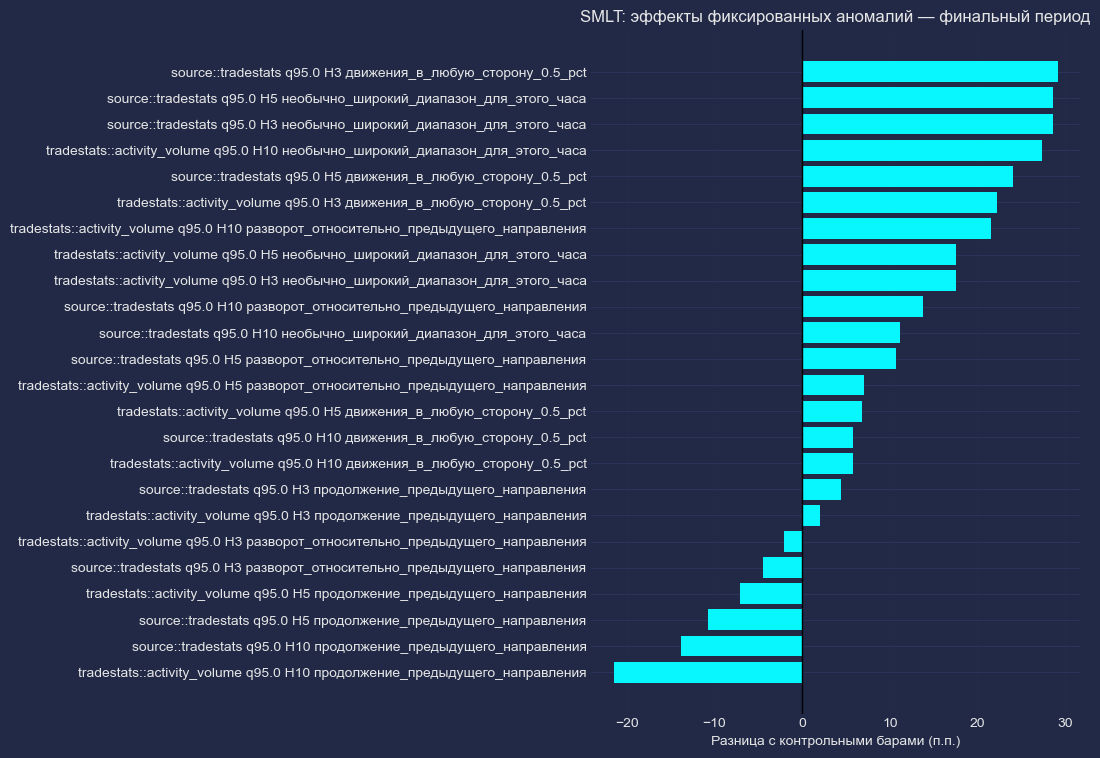

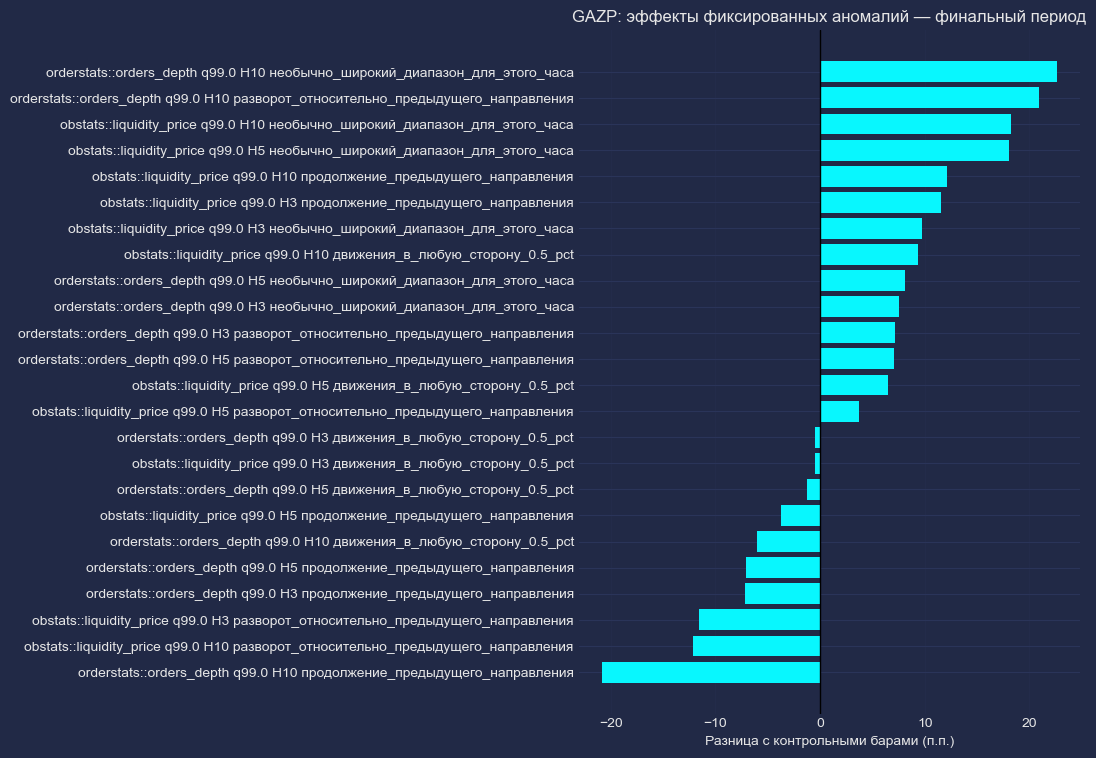

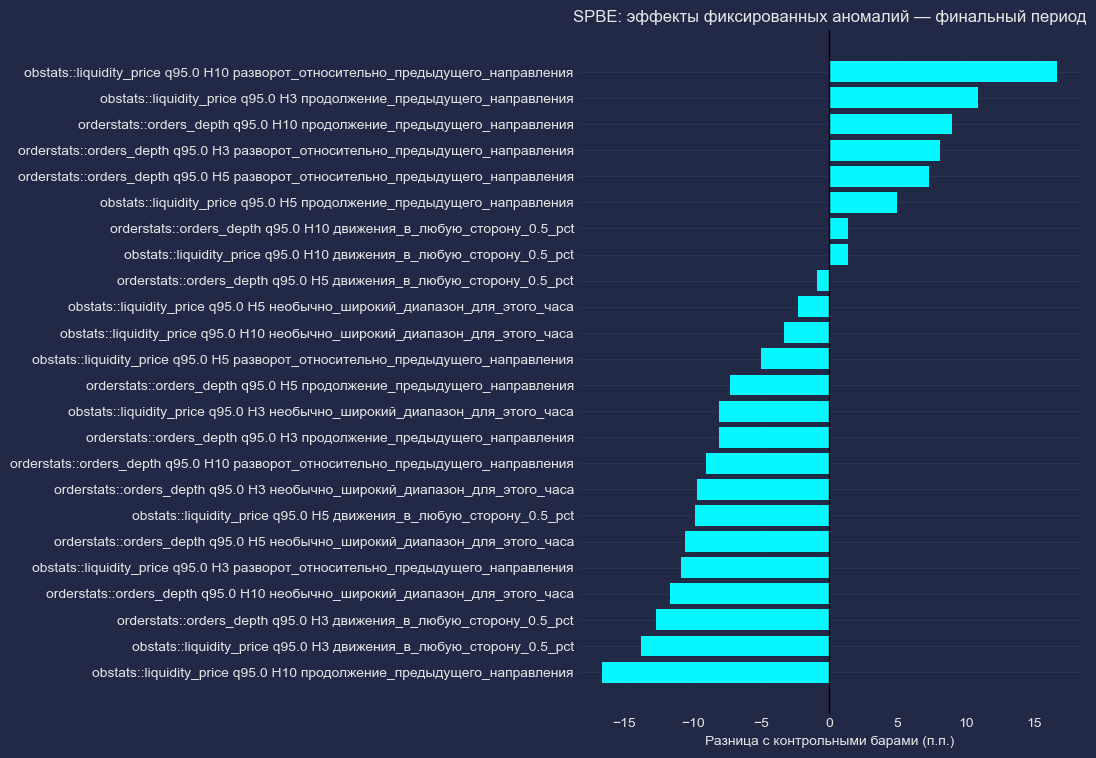

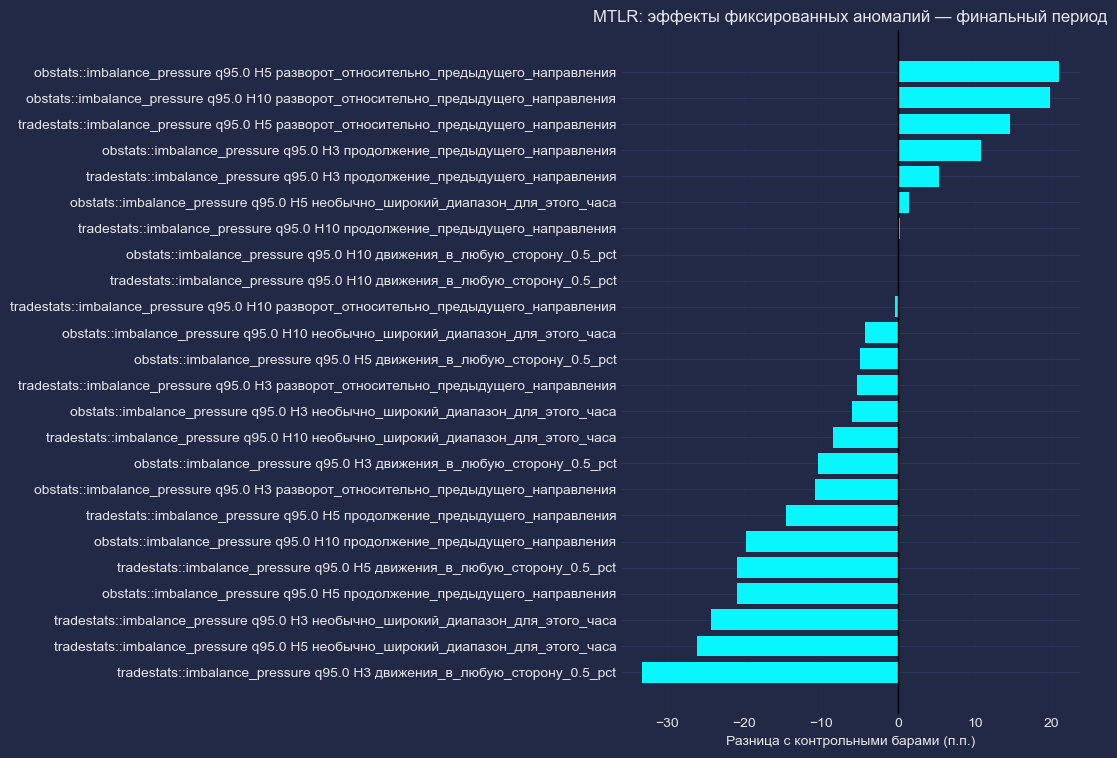

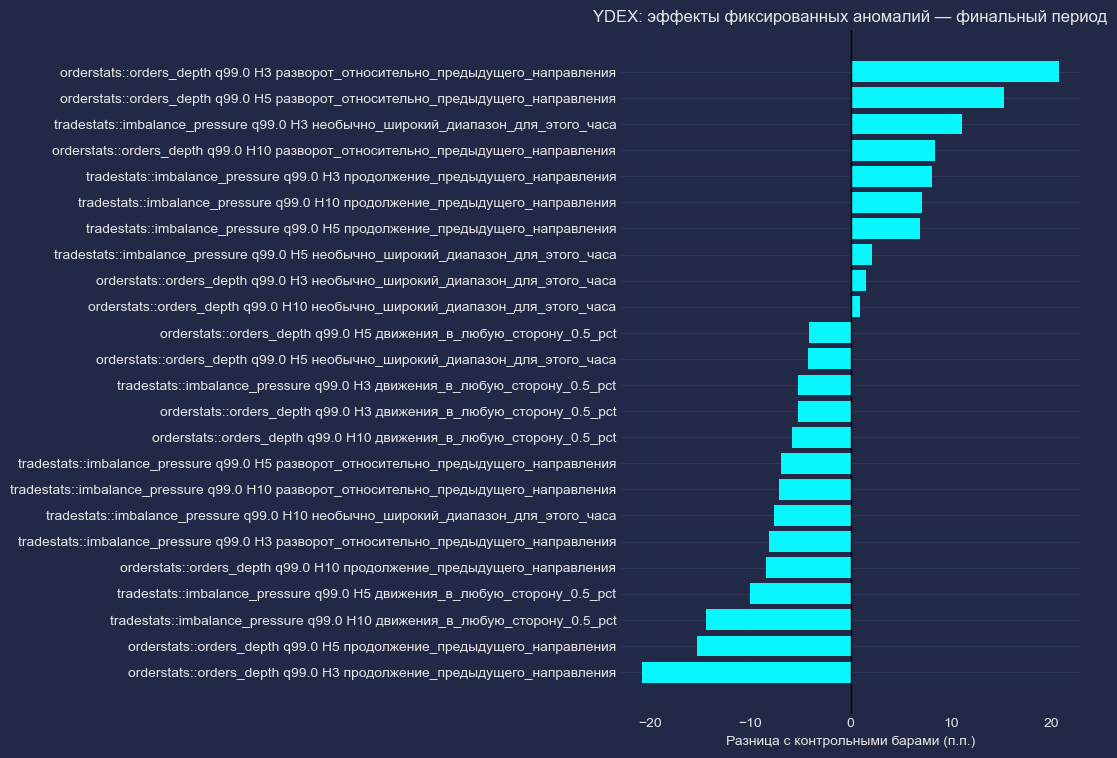

In [16]:

plot_df = final_sc08[
    final_sc08["показатель"].isin([
        "вероятность_движения_в_любую_сторону_0.5_pct",
        "продолжение_предыдущего_направления",
        "разворот_относительно_предыдущего_направления",
        "необычно_широкий_диапазон_для_этого_часа",
    ])
].copy()

for ticker in FIXED_CANDIDATES:
    sub = plot_df[plot_df["тикер"] == ticker].copy()
    if sub.empty:
        continue
    sub["подпись"] = sub["группа"].str.replace("source_family::","",regex=False) + " q" + (sub["порог_аномалии"]*100).round().astype(str) + " H" + sub["горизонт_баров"].astype(str) + " " + sub["показатель"].str.replace("вероятность_","",regex=False)
    sub = sub.sort_values("разница_событие_минус_контроль")
    fig, ax = plt.subplots(figsize=(11, max(3, .32*len(sub))))
    ax.barh(sub["подпись"], sub["разница_событие_минус_контроль"])
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{ticker}: эффекты фиксированных аномалий — финальный период")
    ax.set_xlabel("Разница с контрольными барами (п.п.)")
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()


## 3. Как читать результат и что он НЕ доказывает

- `предварительно_интересно=True` — кандидат для следующего подтверждения, а не доказательство торговой альфы.
- `q_после_BH` — поправка на множественные проверки; порог 0,10 используется только для предварительного отбора, не как финальное подтверждение.
- События прореживаются минимум на 10 баров, но будущие окна всё ещё могут пересекаться при горизонте 10; результаты надо трактовать осторожно.
- Контрольные бары — все допустимые бары без выбранной аномалии в том же сегменте, а не идеально подобранные пары. В следующей версии можно добавить контроль по времени суток и прошлой волатильности.
- Этот ноутбук не запускает настоящую стратегию JERICHON и не доказывает прибыльность. Для этого понадобится подключить конкретную зафиксированную версию стратегии и сравнить её сделки с фильтром режима при одинаковых правилах исполнения.
